In [1]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from scipy.ndimage import label, gaussian_filter
from scipy import ndimage as ndi
from scipy.stats import lognorm
from scipy.optimize import curve_fit
from skimage import measure, morphology
from skimage.segmentation import find_boundaries
import fifpy

In [2]:
#Defining all the required functions

#Fourier Transform Functions
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

#Defining constants
dx = 0.0625
dy = 0.0625

def iterative_filtering1D(field, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30,Xi=Xi)
    fif.run(field)
    print(fif.IMC.shape)
    filtered_signal = np.sum(fif.IMC[index:],axis=0)
    return filtered_signal

def iterative_filtering3D(fieldX, fieldY, fieldZ, index, Xi=1.6):
    fif = fifpy.MIF(NIMFs=4,alpha=30, Xi=Xi)
    fif.run(fieldX)
    mif_x = fif.IMC
    logm = np.array([fif.data['stats_list']['logMx'],fif.data['stats_list']['logMy']]).min(axis=0)
    fif.run(fieldY, M=logm)
    mif_y = fif.IMC
    fif.run(fieldZ, M=logm)
    mif_z = fif.IMC
    filtered_x = np.sum(mif_x[index:], axis=0)
    filtered_y = np.sum(mif_y[index:], axis=0)
    filtered_z = np.sum(mif_z[index:], axis=0)
    return filtered_x, filtered_y, filtered_z

def detect_current_sheets(mod_Jz):

    J2_rms = np.mean(mod_Jz)
    
    # size of grid
    nx, ny = mod_Jz.shape
    
    # global maximum |Jz|
    max_global = np.max(mod_Jz)
    
    # threshold to stop searching for new sheets
    # global_threshold = 0.1 * max_global
    global_threshold = 10 * J2_rms
    
    # keep track of points already assigned to sheets
    visited = np.zeros_like(mod_Jz, dtype=bool)
    
    # list to store all current sheets
    current_sheets = []

    while True:
        
        # mask out already visited cells
        masked_field = np.where(visited, -np.inf, mod_Jz)
        
        # location of largest remaining |Jz|
        max_index = np.unravel_index(np.argmax(masked_field), mod_Jz.shape)
        peak_value = mod_Jz[max_index]
        
        # stop condition
        if peak_value < global_threshold:
            break
        
        # threshold for this sheet
        local_threshold = 0.1 * peak_value
        
        # stack for depth-first search
        stack = [max_index]
        
        # store indices belonging to this sheet
        sheet_points = []
        
        while stack:
            
            i, j = stack.pop()
            
            if visited[i, j]:
                continue
            
            if mod_Jz[i, j] <= local_threshold:
                continue
            
            visited[i, j] = True
            sheet_points.append((i, j))
            
            # check 4 neighbors
            neighbors = [
                (i+1, j),
                (i-1, j),
                (i, j+1),
                (i, j-1)
            ]
            
            for ni, nj in neighbors:
                if 0 <= ni < nx and 0 <= nj < ny:
                    if not visited[ni, nj]:
                        stack.append((ni, nj))
        
        current_sheets.append(sheet_points)

    return current_sheets

def lognorm_mode(shape, scale):
        """Mode of a log-normal with floc=0: scale * exp(-shape**2)."""
        return scale * np.exp(-shape**2)

In [3]:
# =====================================================
# Single-simulation pooled-snapshot M1/M2/M3 analysis
# =====================================================
def analyze_simulation(
    base_path,
    sim_tag="ApJ",                 # <-- new
    snapshots=(40, 45, 50, 55, 60, 65, 70, 75, 80, 85),
    t_ref=40,
    n_iter=1,
    Xi=3.0,
    dx=None, dy=None,
    cache_dir="filtered_cache",
    fits_dir="gaussian_fits_J2_NR",
    out_prefix="J2_NR",
    label_tag=None,
    # M2 / M3 params
    sigma_smooth=3,
    max_len=60,
    step_size=1,
    max_steps=1000,
    arrow_factor=200.0,
    # detection / cleaning
    morph_disk_radius=5,
    min_object_size=500,
):
    """
    Run the full pipeline for a single simulation directory.

    Parameters
    ----------
    base_path : str
        Path to the simulation folder containing B{x,y,z}_<sim_tag>_t<t>.h5.
    sim_tag : str
        Tag in the filename between the field component and the time, e.g.
        "ApJ" for files like Bx_ApJ_t40.h5. Defaults to "ApJ".
    ...
    """
    if dx is None or dy is None:
        raise ValueError("dx and dy must be provided.")

    if label_tag is None:
        label_tag = os.path.basename(os.path.normpath(base_path))

    os.makedirs(cache_dir, exist_ok=True)
    os.makedirs(fits_dir, exist_ok=True)

    # --------------------------------------------
    # STAGE 1: filter + detect for every snapshot
    # --------------------------------------------
    J2_all   = {}
    mask_all = {}

    for t in snapshots:
        print(f"\n--- {label_tag}, t = {t} ---")
        File_Bx = os.path.join(base_path, f'Bx_{sim_tag}_t{t}.h5')
        File_By = os.path.join(base_path, f'By_{sim_tag}_t{t}.h5')
        File_Bz = os.path.join(base_path, f'Bz_{sim_tag}_t{t}.h5')

        # Per-field cache files (same naming pattern, one per component)
        def _cache_path(field_name):
            return os.path.join(
                cache_dir,
                f"{field_name}_filtered_{label_tag}_t{t}_iter{n_iter}_Xi{Xi}.h5"
            )

        cache_Bx = _cache_path("Bx")
        cache_By = _cache_path("By")
        cache_Bz = _cache_path("Bz")
        cache_Jx = _cache_path("Jx")
        cache_Jy = _cache_path("Jy")
        cache_Jz = _cache_path("Jz")

        B_cached = all(os.path.exists(p) for p in (cache_Bx, cache_By, cache_Bz))
        J_cached = all(os.path.exists(p) for p in (cache_Jx, cache_Jy, cache_Jz))

        # ---- filtered B fields ----
        if B_cached:
            print("  loading cached filtered B fields...")
            with h5py.File(cache_Bx, 'r') as f: data_Bx_f = f['Bx'][:]
            with h5py.File(cache_By, 'r') as f: data_By_f = f['By'][:]
            with h5py.File(cache_Bz, 'r') as f: data_Bz_f = f['Bz'][:]
        else:
            print("  computing filtering (slow)...")
            with h5py.File(File_Bx, 'r') as fBx, \
                 h5py.File(File_By, 'r') as fBy, \
                 h5py.File(File_Bz, 'r') as fBz:
                data_Bx = fBx['DS1'][:].T
                data_By = fBy['DS1'][:].T
                data_Bz = fBz['DS1'][:].T
            data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
                data_Bx, data_By, data_Bz, n_iter, Xi=Xi
            )

            common_attrs = dict(n_iter=n_iter, Xi=Xi, t=t,
                                label=label_tag, sim_tag=sim_tag,
                                dx=dx, dy=dy)
            for path, name, arr in [(cache_Bx, 'Bx', data_Bx_f),
                                    (cache_By, 'By', data_By_f),
                                    (cache_Bz, 'Bz', data_Bz_f)]:
                with h5py.File(path, 'w') as f:
                    f.create_dataset(name, data=arr, compression='gzip')
                    for k, v in common_attrs.items():
                        f.attrs[k] = v

        # ---- current density components ----
        if J_cached:
            print("  loading cached J components...")
            with h5py.File(cache_Jx, 'r') as f: Jx = f['Jx'][:]
            with h5py.File(cache_Jy, 'r') as f: Jy = f['Jy'][:]
            with h5py.File(cache_Jz, 'r') as f: Jz = f['Jz'][:]
        else:
            Jx = partial_y_fft(data_Bz_f, dx)
            Jy = -partial_x_fft(data_Bz_f, dy)
            Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)

            common_attrs = dict(n_iter=n_iter, Xi=Xi, t=t,
                                label=label_tag, sim_tag=sim_tag,
                                dx=dx, dy=dy)
            for path, name, arr in [(cache_Jx, 'Jx', Jx),
                                    (cache_Jy, 'Jy', Jy),
                                    (cache_Jz, 'Jz', Jz)]:
                with h5py.File(path, 'w') as f:
                    f.create_dataset(name, data=arr, compression='gzip')
                    for k, v in common_attrs.items():
                        f.attrs[k] = v

        J2 = Jx**2 + Jy**2 + Jz**2

        # detection + morphological cleaning
        sheets = detect_current_sheets(J2)
        mask = np.zeros_like(J2)
        for sheet in sheets:
            for (i, j) in sheet:
                mask[i, j] = 1
        struct = morphology.disk(morph_disk_radius)
        mask = morphology.binary_opening(mask, struct)
        mask = morphology.binary_closing(mask, struct)
        mask = morphology.remove_small_objects(
            mask.astype(bool), min_size=min_object_size
        ).astype(int)

        J2_all[t]   = J2
        mask_all[t] = mask

    # global colour scale across all snapshots
    all_values = np.concatenate([J2_all[t].ravel() for t in snapshots])
    vmax_global = np.percentile(all_values, 99)

    # --------------------------------------------
    # STAGE 2: pooled M1/M2/M3
    # --------------------------------------------
    def gaussian(t, A, mu, sigma, B):
        return A * np.exp(-(t - mu)**2 / (2*sigma**2)) + B

    def get_max_coords(cleaned_mask, J2):
        labeled_mask, num_features = label(cleaned_mask)
        coords = []
        for i in range(1, num_features + 1):
            region = (labeled_mask == i)
            region_vals = J2[region]
            if region_vals.size == 0:
                continue
            max_pos = np.argmax(np.abs(region_vals))
            xs_r, ys_r = np.where(region)
            coords.append((xs_r[max_pos], ys_r[max_pos]))
        return coords, labeled_mask

    # 5 rows, 1 column
    fig, axes = plt.subplots(5, 1, figsize=(6, 22.5))

    ax_img_m1, ax_hist_m1, ax_img_m2, ax_hist_m2, ax_hist_m3 = axes

    # ---------------- IMAGE ROWS — reference snapshot only
    cleaned_mask_ref = mask_all[t_ref]
    J2_ref           = J2_all[t_ref]
    max_coords_ref, labeled_mask_ref = get_max_coords(cleaned_mask_ref, J2_ref)
    boundaries_ref = find_boundaries(labeled_mask_ref)

    #Row 0
    im = ax_img_m1.imshow(J2_ref.T, cmap='Reds', origin='lower', vmax=vmax_global)
    ax_img_m1.contour(boundaries_ref.T, levels=[0.5], colors='white', linewidths=1)
    for x, y in max_coords_ref:
        ax_img_m1.plot(x, y, marker='x', markersize=10,
                       markeredgewidth=1.5, color='yellow')
    ax_img_m1.set_title(rf'{label_tag} (t={t_ref})')
    ax_img_m1.set_xlabel(r'$x/d_p$')
    ax_img_m1.set_ylabel(r'$y/d_p$')

    cbar = fig.colorbar(im, ax=ax_img_m1, fraction=0.046, pad=0.04)
    cbar.set_label(r'$J^2$')

    # Row 2 — descent arrows from reference frame
    J2_smooth_ref = gaussian_filter(J2_ref, sigma=sigma_smooth)
    dJdx_ref, dJdy_ref = np.gradient(J2_smooth_ref)
    descent_dirs_ref = []
    for (x, y) in max_coords_ref:
        grad = np.array([dJdx_ref[x, y], dJdy_ref[x, y]])
        if np.allclose(grad, 0):
            descent_dirs_ref.append(np.array([0.0, 0.0]))
        else:
            descent_dirs_ref.append(-grad / np.linalg.norm(grad))

    im2 = ax_img_m2.imshow(J2_ref.T, cmap='Reds', origin='lower',
                       vmax=vmax_global, aspect='equal', zorder=0)
    ax_img_m2.contour(boundaries_ref.T, levels=[0.5], colors='white',
                  linewidths=1, zorder=2)
    for (x, y), (dx_, dy_) in zip(max_coords_ref, descent_dirs_ref):
        start = (x - 0.5*arrow_factor*dx_, y - 0.5*arrow_factor*dy_)
        end   = (x + 0.5*arrow_factor*dx_, y + 0.5*arrow_factor*dy_)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="red", mutation_scale=10,
                                linewidth=2, zorder=10)
        ax_img_m2.add_patch(arrow)
    ax_img_m2.set_title(rf'{label_tag} (t={t_ref}, descent dir.)')
    ax_img_m2.set_xlabel(r'$x/d_p$')
    ax_img_m2.set_ylabel(r'$y/d_p$')

    cbar2 = ax_img_m2.figure.colorbar(im2, ax=ax_img_m2, fraction=0.046, pad=0.04)
    cbar2.set_label(r'$J^2$')

    # ---------------- POOLED THICKNESSES ----------------
    thicknesses_m1_pooled = []
    thicknesses_m2_pooled = []
    thicknesses_m3_pooled = []

    for t in snapshots:
        cleaned_mask = mask_all[t]
        J2           = J2_all[t]
        max_coords, _ = get_max_coords(cleaned_mask, J2)

        # --- M1
        labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
        for label_id in range(1, labeled_mask_m1.max() + 1):
            region = (labeled_mask_m1 == label_id)
            dist = ndi.distance_transform_edt(region)
            thicknesses_m1_pooled.append(2 * dist.max())

        # --- descent dirs for this t
        J2_smooth = gaussian_filter(J2, sigma=sigma_smooth)
        dJdx, dJdy = np.gradient(J2_smooth)
        descent_dirs = []
        for (x, y) in max_coords:
            grad = np.array([dJdx[x, y], dJdy[x, y]])
            if np.allclose(grad, 0):
                descent_dirs.append(np.array([0.0, 0.0]))
            else:
                descent_dirs.append(-grad / np.linalg.norm(grad))

        # --- M2
        for (x0, y0), (dx_, dy_) in zip(max_coords, descent_dirs):
            x0f, y0f = float(x0), float(y0)

            xf, yf, steps = x0f, y0f, 0
            while steps < max_steps:
                xf_new = xf + dx_*step_size
                yf_new = yf + dy_*step_size
                xi, yi = int(round(xf_new)), int(round(yf_new))
                if (xi < 0 or yi < 0 or
                    xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                    break
                if not cleaned_mask[xi, yi]:
                    break
                xf, yf = xf_new, yf_new
                steps += 1
            dist_forward = np.hypot(xf - x0f, yf - y0f)

            xb, yb, steps = x0f, y0f, 0
            while steps < max_steps:
                xb_new = xb - dx_*step_size
                yb_new = yb - dy_*step_size
                xi, yi = int(round(xb_new)), int(round(yb_new))
                if (xi < 0 or yi < 0 or
                    xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                    break
                if not cleaned_mask[xi, yi]:
                    break
                xb, yb = xb_new, yb_new
                steps += 1
            dist_backward = np.hypot(xb - x0f, yb - y0f)

            total = dist_forward + dist_backward
            if total > 0:
                thicknesses_m2_pooled.append(total)

        # --- M3 + save every fit
        save_folder = os.path.join(fits_dir, label_tag, f"t{t}")
        os.makedirs(save_folder, exist_ok=True)

        for i, ((x, y), (dx_, dy_)) in enumerate(zip(max_coords, descent_dirs)):
            if dx_ == 0 and dy_ == 0:
                continue

            xs, vals = [], []
            for k in range(-max_len, max_len + 1):
                xc = x + k*dx_
                yc = y + k*dy_
                xi, yi = int(round(xc)), int(round(yc))
                if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
                    xs.append(k)
                    vals.append(J2[xi, yi])
            xs = np.array(xs); vals = np.array(vals)
            if len(vals) < 3:
                continue

            A0 = vals.max() - vals.min()
            mu0 = xs[np.argmax(vals)]
            sigma0 = max_len / 4
            B0 = vals.min()

            try:
                popt, _ = curve_fit(gaussian, xs, vals,
                                    p0=[A0, mu0, sigma0, B0])
            except RuntimeError:
                continue

            A, mu, sigma_fit, B = popt
            fwhm = 2*np.sqrt(2*np.log(2))*abs(sigma_fit)
            if 0 < fwhm <= 100:
                thicknesses_m3_pooled.append(fwhm)

            x_dense = np.linspace(xs.min(), xs.max(), 500)
            fit_curve = A*np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B
            fig_fit, ax_fit = plt.subplots()
            ax_fit.plot(xs, vals, 'o', label="sampled profile")
            ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
            ax_fit.set_title(f"{label_tag}, t={t}, sample {i} — FWHM = {fwhm:.2f} px")
            ax_fit.set_xlabel("t (pixels)")
            ax_fit.set_ylabel("Intensity")
            ax_fit.legend()
            fig_fit.savefig(os.path.join(save_folder, f"fit_{i:03d}.png"))
            plt.close(fig_fit)

    # ---------------- POOLED STATS ----------------
    if thicknesses_m1_pooled:
        a = np.array(thicknesses_m1_pooled)
        print(f"[{label_tag}] M1 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")
    if thicknesses_m2_pooled:
        a = np.array(thicknesses_m2_pooled)
        print(f"[{label_tag}] M2 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")
    if thicknesses_m3_pooled:
        a = np.array(thicknesses_m3_pooled)
        print(f"[{label_tag}] M3 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")

    # ---------------- PDF ROWS ----------------
    # Row 1: M1
    x_m1_di = np.array(thicknesses_m1_pooled)
    x_m1_di = x_m1_di[x_m1_di > 0] / 16.0
    if x_m1_di.size > 0:
        s, l, sc = lognorm.fit(x_m1_di, floc=0)
        xs_fit = np.linspace(0, x_m1_di.max(), 300)
        ax_hist_m1.hist(x_m1_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m1.plot(xs_fit, lognorm.pdf(xs_fit, s, l, sc), label="Log-normal fit")
        ax_hist_m1.legend()
    ax_hist_m1.set_xlabel(r"$d_i$")
    ax_hist_m1.set_ylabel("Probability density")
    ax_hist_m1.set_title(rf'M1 PDF ({label_tag}, pooled)')

    # Row 3: M2
    x_m2_di = np.array(thicknesses_m2_pooled)
    x_m2_di = x_m2_di[x_m2_di > 0] / 16.0
    if x_m2_di.size > 0:
        s, l, sc = lognorm.fit(x_m2_di, floc=0)
        xs_fit = np.linspace(0, x_m2_di.max(), 300)
        ax_hist_m2.hist(x_m2_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m2.plot(xs_fit, lognorm.pdf(xs_fit, s, l, sc), label="Log-normal fit")
        ax_hist_m2.legend()
    ax_hist_m2.set_xlabel(r"$d_i$")
    ax_hist_m2.set_ylabel("Probability density")
    ax_hist_m2.set_title(rf'M2 PDF ({label_tag}, pooled)')

    # Row 4: M3
    x_m3_di = np.array(thicknesses_m3_pooled) / 16.0
    if x_m3_di.size > 0:
        s, l, sc = lognorm.fit(x_m3_di, floc=0)
        xs_fit = np.linspace(0, x_m3_di.max(), 300)
        ax_hist_m3.hist(x_m3_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m3.plot(xs_fit, lognorm.pdf(xs_fit, s, l, sc), label="Log-normal fit")
        ax_hist_m3.legend()
    ax_hist_m3.set_xlabel(r"$d_i$")
    ax_hist_m3.set_ylabel("Probability density")
    ax_hist_m3.set_title(rf'M3 PDF ({label_tag}, pooled)')

    plt.tight_layout()
    out_fig = f"{out_prefix}_{label_tag}_M1_M2_M3_pooled.png"
    plt.savefig(out_fig, dpi=300)
    plt.show()

    return {
    "label": label_tag,
    "snapshots": list(snapshots),
    "m1": np.array(thicknesses_m1_pooled),
    "m2": np.array(thicknesses_m2_pooled),
    "m3": np.array(thicknesses_m3_pooled),
    "vmax_global": vmax_global,
    "figure_path": out_fig,
    "max_coords_ref": np.array(max_coords_ref),       # (N, 2) array of CS maxima at t_ref
    "labeled_mask_ref": labeled_mask_ref,             # 2D int array, same shape as J2
    "J2_ref": J2_ref,                                 # the J² field at t_ref
    "t_ref": t_ref,
    "dx": dx,
    "dy": dy,
    }


--- sim2, t = 48 ---
  loading cached filtered B fields...
  loading cached J components...

--- sim2, t = 56 ---
  loading cached filtered B fields...
  loading cached J components...

--- sim2, t = 64 ---
  loading cached filtered B fields...
  loading cached J components...

--- sim2, t = 72 ---
  loading cached filtered B fields...
  loading cached J components...

--- sim2, t = 80 ---
  loading cached filtered B fields...
  loading cached J components...
[sim2] M1 pooled (N=417) mean=21.917, median=18.439, min=11.662, max=57.201
[sim2] M2 pooled (N=417) mean=21.266, median=15.000, min=1.000, max=116.000
[sim2] M3 pooled (N=414) mean=11.103, median=7.280, min=2.182, max=86.141


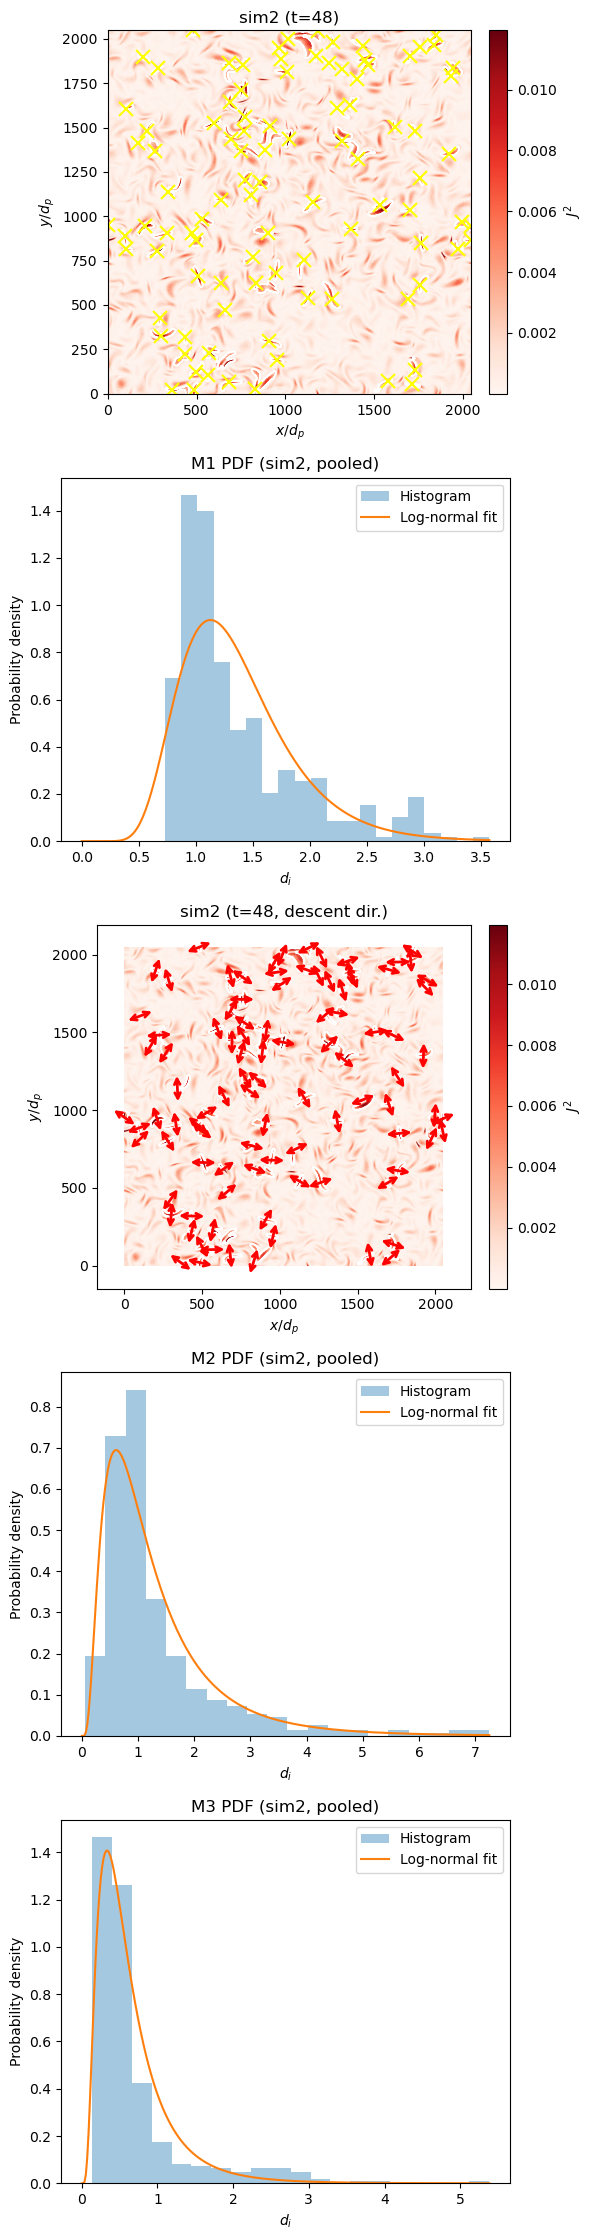

In [4]:
dx = 0.125
dy = 0.125

results = analyze_simulation(
    base_path="/DATA/Nancy_S3_moreppc",
    sim_tag="EL16modesMorePPC",
    snapshots=[48,56,64,72,80],
    t_ref=48,
    n_iter=1, Xi=3.0,
    dx=dx, dy=dy,
    label_tag="sim2",
)

In [7]:
base_dir = "/DATA/Nancy_S3_moreppc/cs_analysis"
label = results["label"]
dx    = results["dx"]
t_ref = results["t_ref"]
os.makedirs(base_dir, exist_ok=True)   # create it if it doesn't exist yet

np.savetxt(os.path.join(base_dir, 'thicknesses_m1_pooled.csv'),
           results["m1"], delimiter=',', header='thickness_di', comments='')
np.savetxt(os.path.join(base_dir, 'thicknesses_m2_pooled.csv'),
           results["m2"], delimiter=',', header='thickness_di', comments='')
np.savetxt(os.path.join(base_dir, 'thicknesses_m3_pooled.csv'),
           results["m3"], delimiter=',', header='thickness_di', comments='')

In [8]:
np.savetxt(os.path.join(base_dir, f"max_coords_t{t_ref}.csv"),
           results["max_coords_ref"] * dx, delimiter=',',
           header='x_di,y_di', comments='')

In [9]:
# labeled mask — defines the CS regions; contours = find_boundaries(labeled_mask)
with h5py.File(os.path.join(base_dir, f"cs_mask_{label}_t{t_ref}.h5"), "w") as f:
    f.create_dataset("labeled_mask",
                     data=results["labeled_mask_ref"],
                     compression="gzip")
    f.attrs["dx"]    = dx
    f.attrs["t"]     = t_ref
    f.attrs["label"] = label
    f.attrs["description"] = (
        "Integer labels: 0 = no CS, positive integers = CS region ID. "
        "Contours: skimage.segmentation.find_boundaries(labeled_mask)."
    )

# J² field at the same snapshot
with h5py.File(os.path.join(base_dir, f"J2_{label}_t{t_ref}.h5"), "w") as f:
    f.create_dataset("J2",
                     data=results["J2_ref"],
                     compression="gzip")
    f.attrs["dx"]    = dx
    f.attrs["t"]     = t_ref
    f.attrs["label"] = label

print("wrote files to", base_dir)

wrote files to /DATA/Nancy_S3_moreppc/cs_analysis
